In [66]:
import numpy as np
import altair as alt
import json
import seaborn as sns 
from evaluation.avalanche_criterion import avalanche_criterion
from evaluation.fixed_points import fixed_ponts
from evaluation.uniformity import get_ddt
from evaluation.linearity import evaluate
from sboxes.loader import load as load_sbox
from sboxes import SBox
from sboxes.loader import load as load_sbox
from evaluation.identity_sbox import IdentitySBox

from evaluation.graphics.graphics_with_altair import (
    compare_tv_distance_altair,
    compare_max_probability_altair,
    compare_mixing_times_altair,
    compare_mixing_times_spectrals_altair
)

# Para que Altair muestre los charts en el notebook
alt.renderers.enable('default')

bits = 6
bits_str = str(bits)

In [67]:
from evaluation.fixed_points      import fixed_ponts

number_of_owns = 50
own_sboxes_index = range(1,number_of_owns+1)

selected = []

for i in own_sboxes_index:
    with open(f"data/{bits_str}x{bits_str}_sboxes/sbox_{bits_str}_{i}.json", "r", encoding="utf-8") as f:
        data = json.load(f)
        table = list(map(lambda x: hex(x), data["best"]))
        n_in  = int(np.log2(len(table)))                    # size of the input
        n_out = int(np.ceil(np.log2(max(data["best"])+1)))  # size of the output
        name = f"Variant #{i}"    
        sbox = SBox(n_in, n_out, table, name)                    
        fijos = fixed_ponts(sbox, detail=True)[1]
        if fijos == 0:
            selected.append(i)
print(f"{selected}")

[2, 3, 5, 6, 7, 8, 9, 10, 12, 16, 17, 20, 21, 26, 28, 30, 32, 34, 35, 40, 46, 47, 48, 50]


In [ ]:
selected = [3, 9, 10, 35, 47]

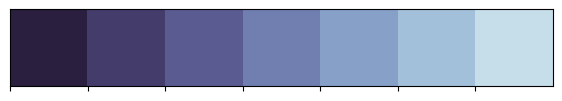

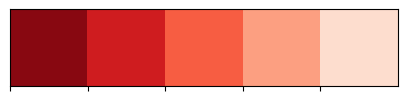

In [69]:
number_of_owns = len(selected)
own_sboxes_index = selected

COLORS_FOR_OWNS = sns.color_palette("ch:s=.25,rot=-.25", n_colors=number_of_owns) [::-1]
#sns.palplot(sns.color_palette("Reds", n_colors=10))[::-3]  # Colores para las S-Boxes propias
COLORS_FOR_CLASICS = sns.color_palette("Reds", n_colors=14)[::-3]
sns.palplot(COLORS_FOR_OWNS)
sns.palplot(COLORS_FOR_CLASICS)

In [70]:
to_proof = ["fides_6_APN"]
specs_clasics = []

for sbox_link in to_proof:
    sbox = load_sbox(f"data/clasics/{sbox_link}.json")
    specs_clasics.append({
        'name': sbox.name,
        'table': sbox.table.tolist(),
        'n_in': sbox.input_size,
        'n_out': sbox.output_size,
        'color': COLORS_FOR_CLASICS[len(specs_clasics) % len(COLORS_FOR_CLASICS)],
        'sbox': sbox
        
    })
    print(f"Procesando S-Box: {sbox.name} ({sbox.input_size}x{sbox.output_size})")

Procesando S-Box: FIDES_6 (6x6)


In [71]:
specs_owns = []

for i in own_sboxes_index:

    with open(f"data/{bits_str}x{bits_str}_sboxes/sbox_{bits_str}_{i}.json", "r", encoding="utf-8") as f:
        data = json.load(f)
    
        table = list(map(lambda x: hex(x), data["best"]))
        n_in  = int(np.log2(len(table)))                    # size of the input
        n_out = int(np.ceil(np.log2(max(data["best"])+1)))  # size of the output
        name = f"Variant #{i}"
            
        sbox = SBox(n_in, n_out, table, name)                    
        specs_owns.append({
            "name": name,              
            "table": data["best"],
            "n_in": n_in,
            "n_out": n_out,
            "color": COLORS_FOR_OWNS[len(specs_owns) % len(COLORS_FOR_OWNS)],
            "sbox":  sbox
        })

print(f"{len(specs_owns)} S-Boxes cargadas desde data.json")


7 S-Boxes cargadas desde data.json


In [72]:

specs = specs_clasics + specs_owns

import matplotlib.colors as mcolors
for spec in specs:
    spec['color'] = mcolors.to_hex(spec['color'])

In [73]:
chart_tv = compare_tv_distance_altair(
    specs,
    r_values=list(range(1,16)),
    log_scale=True,
    detail=False
)
chart_tv

alt.Chart(...)

In [74]:
chart_mp = compare_max_probability_altair(
    specs,
    r_values=list(range(1,11)),
    log_scale=False,
    detail=True
)
chart_mp

|   r |   FIDES_6 |   Variant #10 |   Variant #26 |   Variant #3 |   Variant #34 |   Variant #35 |   Variant #47 |   Variant #9 |
|----:|----------:|--------------:|--------------:|-------------:|--------------:|--------------:|--------------:|-------------:|
|   1 | 0.0625    |     0.0625    |     0.0625    |    0.0625    |     0.09375   |     0.0625    |     0.09375   |    0.09375   |
|   2 | 0.0234375 |     0.0273438 |     0.0253906 |    0.0273438 |     0.0292969 |     0.0273438 |     0.0273438 |    0.0263672 |
|   3 | 0.0167423 |     0.0178223 |     0.0177307 |    0.0175171 |     0.0174561 |     0.0175171 |     0.0176086 |    0.0180664 |
|   4 | 0.0159996 |     0.0161085 |     0.016181  |    0.0161133 |     0.0161848 |     0.0161638 |     0.0161324 |    0.0161686 |
|   5 | 0.0159144 |     0.0159227 |     0.0159301 |    0.0159156 |     0.0159134 |     0.0159164 |     0.0159176 |    0.0159188 |
|   6 | 0.0159013 |     0.0158795 |     0.0158822 |    0.0158793 |     0.0158821 |     0.0

alt.Chart(...)

In [75]:
chart_mix = compare_mixing_times_altair(
    specs,
    epsilons=[10**(-i) for i in range(1,10)],
    max_steps=10000,
    log_scale=True,
)
chart_mix

[0.1, 0.01, 0.001, 0.0001, 1e-05, 1e-06, 1e-07, 1e-08, 1e-09]


alt.Chart(...)

In [76]:
chart_spec = compare_mixing_times_spectrals_altair(
    specs,
    epsilons=[10**(-i) for i in range(1,10)],
    max_steps=10000,
    log_scale=True,
)
chart_spec

alt.Chart(...)

# Clasicas


=== Métricas de S-Boxes ===
       name  uniformity  max_ddt  fixed_points  non_linearity  avg_sac  max_std_sac
    FIDES_6           4       64             0           23.0 0.510417     0.079502
 Variant #3           4       64             0           20.0 0.517361     0.130104
 Variant #9           6       64             0           22.0 0.510417     0.078644
Variant #10           4       64             0           20.0 0.496528     0.085898
Variant #26           4       64             0           20.0 0.508681     0.098271
Variant #35           4       64             0           20.0 0.505208     0.102062
Variant #34           6       64             0           22.0 0.484375     0.086527
Variant #47           6       64             0           22.0 0.506944     0.091406


c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


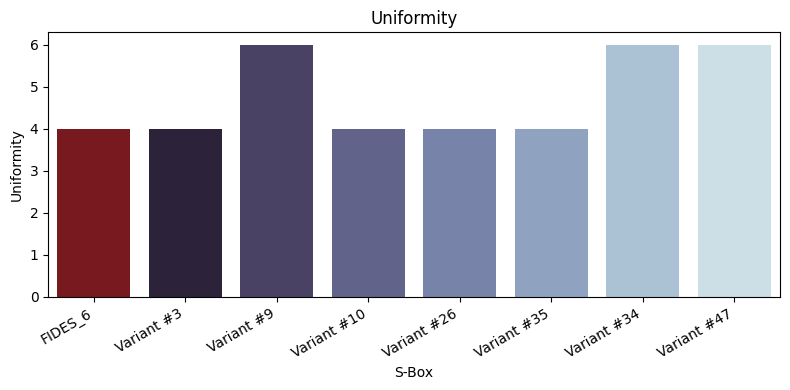

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


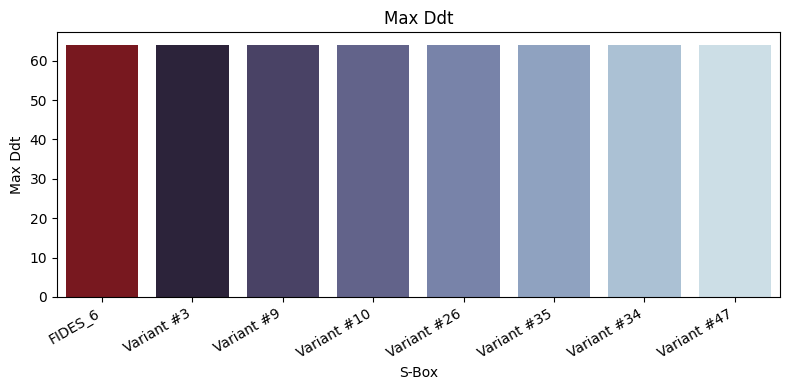

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


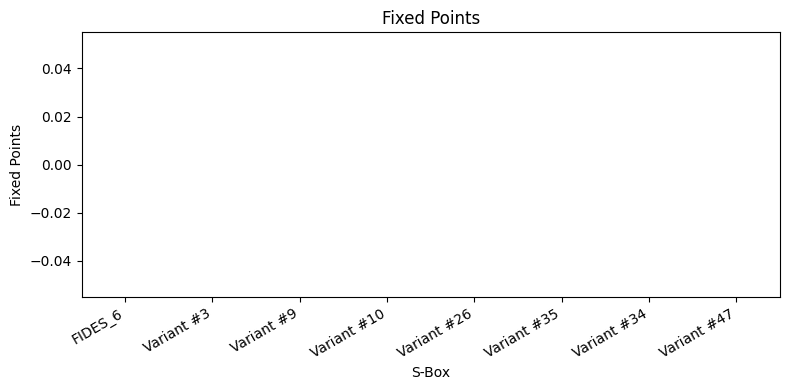

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


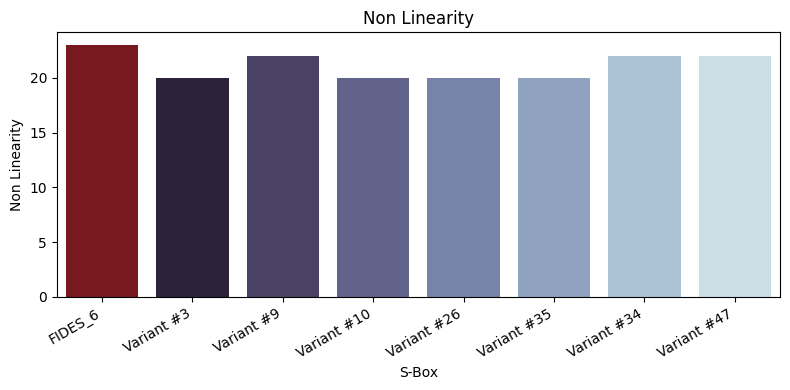

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


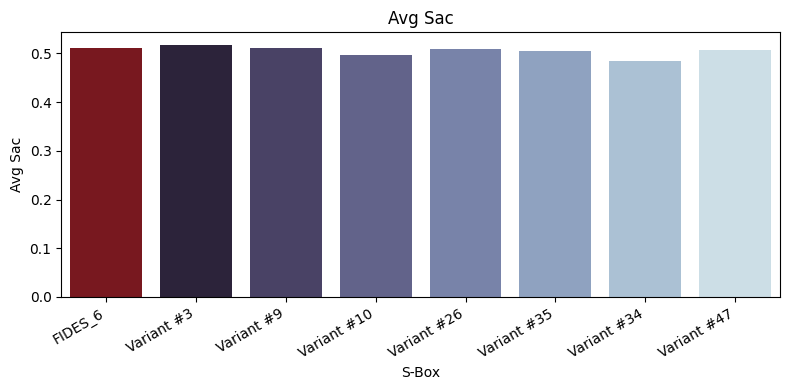

c:\Users\surface\GitHub\evaluation_sboxes\evaluation\sbox_metrics_analysis.py:62: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


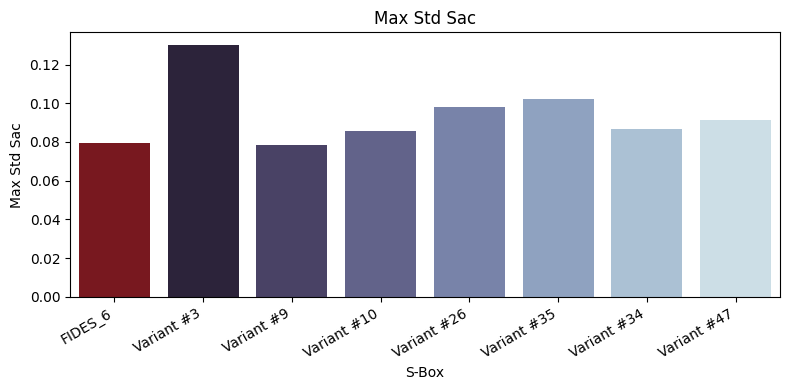

,name,uniformity,max_ddt,fixed_points,non_linearity,avg_sac,max_std_sac
0,FIDES_6,4,64,0,23.0,0.510417,0.079502
1,Variant #3,4,64,0,20.0,0.517361,0.130104
2,Variant #9,6,64,0,22.0,0.510417,0.078644
3,Variant #10,4,64,0,20.0,0.496528,0.085898
4,Variant #26,4,64,0,20.0,0.508681,0.098271
5,Variant #35,4,64,0,20.0,0.505208,0.102062
6,Variant #34,6,64,0,22.0,0.484375,0.086527
7,Variant #47,6,64,0,22.0,0.506944,0.091406


In [77]:
from evaluation.sbox_metrics_analysis import run_all_metrics

run_all_metrics(specs)

# Ranking

In [78]:
import pandas as pd

# Carga el resumen de métricas generado por run_all_metrics
df = pd.read_csv('sbox_metrics_summary.csv')

# Calcula desviación de avg_sac respecto a 0.5 (ideal SAC = 0.5)
df['sac_error'] = (df['avg_sac'] - 0.5).abs()

# Genera rankings individuales (menor es mejor salvo non_linearity)
df['r_uniformity']    = df['uniformity'].rank(ascending=True)
df['r_max_ddt']       = df['max_ddt'].rank(ascending=True)
df['r_fixed_points']  = df['fixed_points'].rank(ascending=True)
df['r_non_linearity'] = df['non_linearity'].rank(ascending=False)
df['r_sac_error']     = df['sac_error'].rank(ascending=True)
df['r_max_std_sac']   = df['max_std_sac'].rank(ascending=True)

# Suma de rangos como puntaje agregado
rank_cols = ['r_uniformity','r_max_ddt','r_fixed_points',
             'r_non_linearity','r_sac_error','r_max_std_sac']
df['total_rank'] = df[rank_cols].sum(axis=1)

# Ordena y muestra top 5
top5 = df.sort_values('total_rank').reset_index(drop=True)
to_display = top5[['name','total_rank','non_linearity','uniformity',
                   'fixed_points','avg_sac','max_ddt','max_std_sac']].head(5)

print(to_display.to_markdown(index=False))
#import ace_tools as tools; tools.display_dataframe_to_user(name="Top 5 S-Boxes por puntaje agregado", dataframe=to_display)


| name        |   total_rank |   non_linearity |   uniformity |   fixed_points |   avg_sac |   max_ddt |   max_std_sac |
|:------------|-------------:|----------------:|-------------:|---------------:|----------:|----------:|--------------:|
| FIDES_6     |         20.5 |              23 |            4 |              0 |  0.510417 |        64 |     0.0795018 |
| Variant #10 |         22.5 |              20 |            4 |              0 |  0.496528 |        64 |     0.085898  |
| Variant #9  |         25.5 |              22 |            6 |              0 |  0.510417 |        64 |     0.0786441 |
| Variant #47 |         27   |              22 |            6 |              0 |  0.506944 |        64 |     0.0914059 |
| Variant #35 |         27.5 |              20 |            4 |              0 |  0.505208 |        64 |     0.102062  |
